# 01 — Timestral fundamentals
Official Mistral Timestral API, univariate and multivariate zero-shot forecasts. Model weights download on first run. Start with `Timestral-5M` for a lightweight CPU demo.

In [1]:
%pip install -q numpy pandas matplotlib scikit-learn torch safetensors huggingface_hub git+https://github.com/mistralai/timestral.git@a534bdbd244d64f3d9d743f46c7bf6fc330ed4ff


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: /Users/linghuang/miniconda3/envs/llm/bin/python -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from timestral import TimestralForecaster
rng = np.random.default_rng(42)
t = np.arange(240)
views = 500 + 1.2*t + 45*np.sin(2*np.pi*t/7) + rng.normal(0, 18, len(t))
joins = 80 + .22*t + 12*np.sin(2*np.pi*t/7) + rng.normal(0, 6, len(t))
model = TimestralForecaster.from_pretrained("mistralai/Timestral-5M")
horizon = 14
forecast = model.forecast(views, prediction_length=horizon)
print("Quantiles:", forecast.quantiles.shape)
print("Median:", forecast.median.shape)

/Users/linghuang/miniconda3/envs/llm/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Fetching 2 files: 100%|██████████| 2/2 [00:00<00:00, 40721.40it/s]

Quantiles: torch.Size([1, 1, 14, 21])
Median: torch.Size([1, 1, 14])


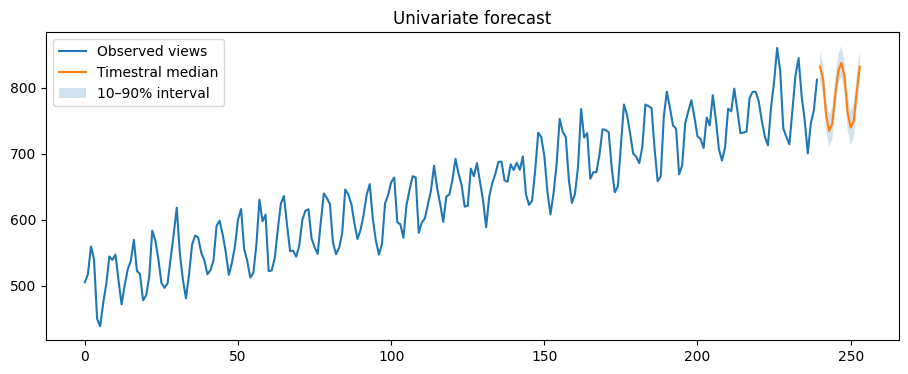

In [3]:
p50 = forecast.median.reshape(-1)
p10 = forecast.quantile(0.1).reshape(-1)
p90 = forecast.quantile(0.9).reshape(-1)
plt.figure(figsize=(11,4))
plt.plot(t,views,label="Observed views")
future=np.arange(len(t),len(t)+horizon)
plt.plot(future,p50,label="Timestral median")
plt.fill_between(future,p10,p90,alpha=.2,label="10–90% interval")
plt.legend();plt.title("Univariate forecast");plt.show()

Multivariate median shape: torch.Size([1, 2, 14])


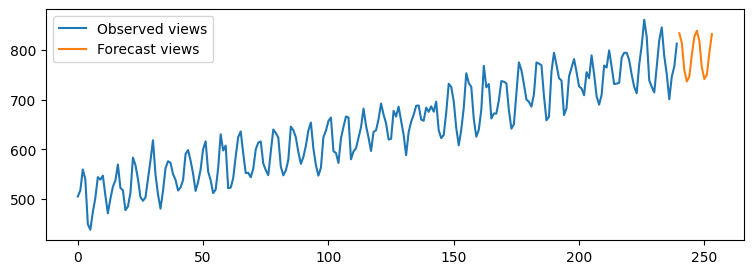

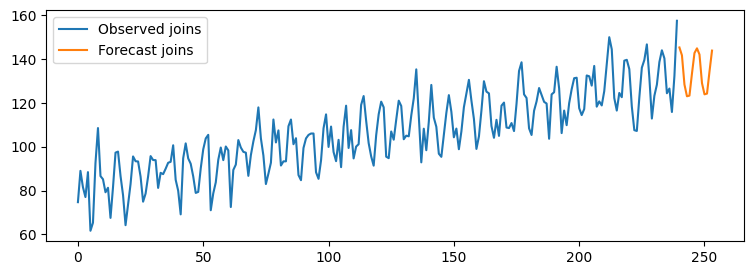

In [4]:
context=np.stack([views, joins])[None,:,:]  # (batch=1, variates=2, time=240)
multi=model.forecast(context,prediction_length=14)
print("Multivariate median shape:",multi.median.shape)
for i,label in enumerate(["views","joins"]):
    plt.figure(figsize=(9,3))
    plt.plot(t,context[0,i],label="Observed "+label)
    plt.plot(future,multi.median[0,i],label="Forecast "+label)
    plt.legend();plt.show()

**Note:** Synthetic data only. Quantile intervals express model uncertainty, not causal explanations. See the [official repository](https://github.com/mistralai/timestral).